# Step 4 — Transit search with TLS, explained on four real light curves

This notebook is a *walkthrough* of what `src/search.py` has to do. It does not
write `search.py` — it runs every piece of the search by hand, on four flattened
light curves that already exist in `data/lc_flat/`, and explains **what each
variable is, what each parameter does, and why we choose it**.

Where we are in the pipeline (see `docs/PLAN_milestone1.md`, §6):

| step | module | reads | writes |
|---|---|---|---|
| 1 | `src/targets.py` | TIC catalog | `data/targets/sector_104.parquet` (stars + `rad`, `mass`) |
| 2 | `src/fetch.py` | MAST | `data/lc_raw/**.fits`, `sector_104_manifest.parquet` |
| 3 | `src/detrend.py` | raw FITS | `data/lc_flat/{tic}.parquet`, `sector_104_detrend.parquet` |
| **4** | **`src/search.py`** | **`data/lc_flat/{tic}.parquet` + `rad`, `mass` from step 1** | **`data/search/sector_104.parquet` — one row per star** |
| 5 | `src/vet.py` | step 4 table | vetted table (thresholds live *here*, not in step 4) |

The contract for step 4 is simple: **for every flattened light curve, run
Transit Least Squares (TLS) once, and record the best periodic transit-like
signal it found — period, epoch, depth, duration, and how significant it is.**
No thresholding: we store everything and decide later, in vetting.

Sections:

1. Load the inputs and look at what a flattened light curve contains
2. What TLS actually does (the idea, in plain words)
3. Every TLS input parameter, one by one, and the value we use
4. Run TLS on one star and read every output field
5. Plots you should always look at: periodogram, phase fold, transit marks
6. Turn it into a function and run it on the four stars → the table `search.py` must produce
7. Optional second pass: mask the best signal and search again
8. Complement: the same recipe on a star with a *known* planet (LHS 3844, already in our data)
9. Checklist for writing `search.py`

## 1. Inputs

### 1.1 Setup

The same conventions as `detrend.py`: `DATA_DIR` comes from `.env`, the flattened
light curves live in `DATA_DIR/lc_flat/`, one parquet per TIC ID.

In [1]:
import os
import time
from pathlib import Path

import dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transitleastsquares import transitleastsquares, transit_mask, cleaned_array

dotenv.load_dotenv(Path("..") / ".env")
SECTOR = int(os.environ["SECTOR"])
DATA_DIR = Path("..") / "data"          # the notebook runs from notebooks/; search.py uses DATA_DIR from .env
FLAT_DIR = DATA_DIR / "lc_flat"

plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["figure.dpi"] = 110
print("sector", SECTOR, "| flattened light curves on disk:", len(list(FLAT_DIR.glob("*.parquet"))))

sector 104 | flattened light curves on disk: 4694


### 1.2 Which stars

`search.py` will iterate over the rows of `sector_104_detrend.parquet` that have
`status == "ok"` — exactly the list `detrend.py` produced. Here we take the first
four of them, which is what `--limit 4` would give. They are not chosen for being
interesting; they are simply the first four. Most stars in a sector show *no*
planet, so "what does a non-detection look like" is the most common case and the
one you must recognise.

We also need two numbers per star from the **target table** (step 1): the stellar
radius `rad` and mass `mass` (solar units, from the TIC). TLS uses them to decide
which orbital periods and transit durations are physically possible (§3).

In [2]:
detrend = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}_detrend.parquet")
targets = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}.parquet").set_index("tic_id")
manifest = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}_manifest.parquet").set_index("tic_id")

ok = detrend[detrend["status"] == "ok"]
stars = ok.head(4)["tic_id"].astype(int).tolist()

# one overview table: what detrend measured + what the TIC says about the star + which light curve we have
overview = pd.concat(
    [
        ok.set_index("tic_id").loc[stars, ["n_out", "std_flat", "med_err"]],
        targets.loc[stars, ["tmag", "teff", "rad", "mass", "dist_pc", "contratio"]],
        manifest.loc[stars, ["author", "cadence_s"]],
    ],
    axis=1,
)
overview

,n_out,std_flat,med_err,tmag,teff,rad,mass,dist_pc,contratio,author,cadence_s
tic_id,,,,,,,,,,,
6283622,8794,4318.109258,4318.109258,12.8792,3463.0,0.330129,0.311241,56.9257,0.040248,QLP,200.0
6283851,8568,2524.007152,2846.335992,11.5831,3494.0,0.386040,0.375638,38.0056,0.920828,QLP,200.0
6283857,8528,6584.929333,6584.929333,12.3100,3378.0,0.304291,0.281519,37.9785,2.704274,QLP,200.0
6284143,8794,4101.995181,4101.995181,12.5855,3701.0,0.529463,0.526408,99.4648,0.332101,QLP,200.0


Reading that table:

- `n_out` — number of cadences after quality masking and flare clipping (~8,800 for a 200-s QLP light curve over ~24 days).
- `std_flat` — robust scatter of the flattened flux, in **ppm** (parts per million). This is the noise level per point. A transit must be deep enough, and repeat often enough, to stand out from it.
- `med_err` — median of the per-point error bar, also ppm. `detrend.py` checks that `std_flat / med_err ≈ 1`.
- `rad`, `mass` — stellar radius and mass in solar units. Typical for our M dwarfs: 0.3–0.5.
- `contratio` — flux from neighbours falling in the aperture divided by the star's own flux. Large values (> 1) mean the light curve is dominated by *other* stars; a transit found there may belong to a neighbour. Not used by TLS, but you will want it in vetting.
- `author`, `cadence_s` — which pipeline made the light curve and its exposure time. QLP 200 s here.

### 1.3 What is inside one flattened light curve

`detrend.py` wrote five columns. Let's load one and plot the raw normalised flux
with the fitted trend, and the flattened flux that TLS will actually see.

In [3]:
def load_flat(tic_id: int) -> pd.DataFrame:
    return pd.read_parquet(FLAT_DIR / f"{tic_id}.parquet")

lc = load_flat(stars[0])
print(lc.describe().T[["count", "mean", "std", "min", "max"]])
print("time span:", round(lc["time"].max() - lc["time"].min(), 2), "days")

           count         mean           std          min          max
time      8794.0  4191.152956  7.906161e+00  4178.860123  4204.297611
flux      8794.0     0.999896  4.715237e-03     0.957860     1.024397
flux_err  8794.0     0.004318  8.674111e-19     0.004318     0.004318
trend     8794.0     0.998539  1.055629e-02     0.911422     1.008845
flux_raw  8794.0     0.998447  1.245428e-02     0.875874     1.023694
time span: 25.44 days


- `time` — **BTJD** = BJD − 2 457 000, in days. All TESS products use it. The sector spans ~24–27 days, with a gap in the middle (data downlink at perigee).
- `flux_raw` — flux normalised so its median is 1, *before* flattening. It contains the star's slow variability and instrument drifts.
- `trend` — the smooth curve wotan fitted to `flux_raw` (biweight, 0.5-day window).
- `flux` — `flux_raw / trend`. This is flat around 1 and is the input to TLS. A transit of depth *d* shows up as points at `1 − d`.
- `flux_err` — the per-point uncertainty (QLP gives none, so `detrend.py` filled in a robust scatter estimate — that is why `flux_err` is constant for this star).

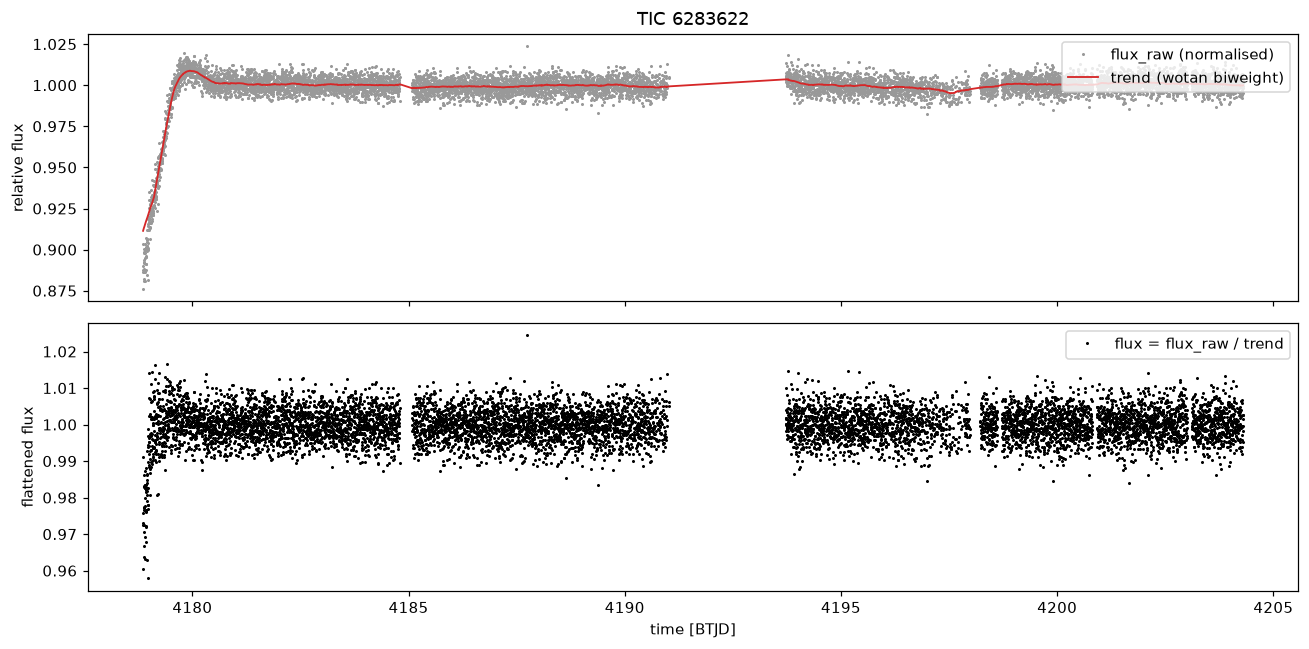

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(lc["time"], lc["flux_raw"], ".", ms=2, color="0.6", label="flux_raw (normalised)")
axes[0].plot(lc["time"], lc["trend"], "-", color="C3", lw=1.2, label="trend (wotan biweight)")
axes[0].legend(loc="upper right"); axes[0].set_ylabel("relative flux")
axes[1].plot(lc["time"], lc["flux"], ".", ms=2, color="k", label="flux = flux_raw / trend")
axes[1].legend(loc="upper right"); axes[1].set_ylabel("flattened flux"); axes[1].set_xlabel("time [BTJD]")
axes[0].set_title(f"TIC {stars[0]}")
plt.tight_layout()

## 2. What TLS does, in plain words

A transiting planet produces a dip that is (i) small, (ii) short (hours), and
(iii) **strictly periodic**. Any single dip can be noise; the power of a search
algorithm comes from *folding*: if you guess the right period *P*, all the
transits line up at the same phase and their signal adds up while the noise
averages out.

TLS (Hippke & Heller 2019) does the following, for a **grid of trial periods**:

1. **Fold** the light curve on the trial period *P* (i.e. compute `phase = ((time − T0) / P) mod 1` and sort by phase).
2. Slide a **transit-shaped template** (a realistic limb-darkened transit, not a box — that is the difference from BLS) across the folded curve, for a **grid of durations**.
3. For every (phase, duration) compute the χ² of "template" vs "flat line". Keep the best χ² for that period.
4. Result: one number per period, the **SR** (signal residue). Normalise it into the **SDE** (Signal Detection Efficiency): $\text{SDE}(P) = \frac{\text{SR}(P) - \langle \text{SR} \rangle}{\sigma_{\text{SR}}}$, i.e. "how many standard deviations above the typical period is this one".

The period with the highest SDE is the candidate. **SDE ≈ 7–9 is the usual
"look at this" threshold**; below that, the peak is not distinguishable from
the peaks noise alone produces. The TLS paper calibrates this: SDE = 9 ↔
false-alarm probability ≈ 10⁻⁴ for white noise. Real light curves have red
noise, so treat those numbers as optimistic — that is what injection/recovery
(plan §6) is for.

Cost: (number of periods) × (number of durations) × (number of points).
For one sector with 200-s cadence: ~10⁴ periods × ~40 durations × ~9,000 points
→ tens of seconds per star on one core. That is why the search step is
parallelised over stars, one thread per star.

## 3. Every TLS input parameter, and the value we use

TLS is used in two lines:

```python
model = transitleastsquares(time, flux, flux_err)   # 1. hand over the data
results = model.power(**params)                     # 2. run the search
```

**Constructor arguments** (the data):

| argument | what it is | our source |
|---|---|---|
| `t` | time array, days, any zero point (we use BTJD) | `lc["time"]` |
| `y` | flux normalised to 1 out of transit | `lc["flux"]` |
| `dy` | per-point flux uncertainty, same units as `y`. Used as weights in χ². If omitted TLS uses the scatter of `y`. | `lc["flux_err"]` |

The arrays must be finite and `t` must be sorted. `detrend.py` already dropped
NaNs; `cleaned_array(t, y, dy)` from TLS is a cheap safety net that removes any
non-finite entries and casts to float64 — worth calling in `search.py`.

**`power()` keyword arguments** — the table below lists all the ones that
matter. The right-hand column is what we will use for a one-sector M-dwarf
search and *why*.

| parameter | default | meaning | ours & why |
|---|---|---|---|
| `R_star`, `M_star` | 1.0, 1.0 (Sun) | Stellar radius and mass, solar units. Used to build the **period grid** (Ofir 2014: the spacing between trial periods is set by how fast the transit duration changes with period, which depends on the stellar density) and the **duration prior** (Kepler's law gives the expected duration for each period; TLS only tests durations that are physically plausible). | `targets.rad`, `targets.mass` — the TIC values. A 0.3 R☉ star has transits ~2× shorter than the Sun; telling TLS this is what "improves the duration prior" in the plan. |
| `R_star_min/max`, `M_star_min/max` | 0.13–3.5 R☉, 0.1–1.0 M☉ | Allowed range around `R_star`/`M_star`. TLS **raises `ValueError`** if `R_star` falls outside `[R_star_min, R_star_max]`. | Our target list has stars down to `rad = 0.128` and `mass = 0.103` — *below the defaults*. Pass `R_star_min=0.1, M_star_min=0.05` (and `*_max=1.0`) explicitly or those stars will crash. |
| `period_min` | 0 | Shortest trial period, days. | `0.5` per the plan. Note: known ultra-short-period planets exist (LHS 3844 b, P = 0.46 d, *is* in this sector!). Consider `0.3`; the cost is small because short periods need few grid points. |
| `period_max` | ∞ (→ set by `n_transits_min`) | Longest trial period, days. | `time_span / 2` ≈ 12 d, so that ≥ 2 transits fit. A single dip is not periodic evidence. |
| `n_transits_min` | 2 | Minimum number of transits that must fit in the baseline; also caps the period grid. | Leave at 2 (equivalent to our `period_max`). |
| `oversampling_factor` | 3 | How densely the period grid samples the optimal Ofir spacing. Higher = less chance to *miss* a peak between grid points, linearly more expensive. | `3` — the paper's recommendation; `5` for a final careful pass. |
| `duration_grid_step` | 1.1 | Successive trial durations are multiplied by this factor (a log grid). 1.1 → ~10 % steps. | `1.1`. Smaller = more durations = slower. |
| `transit_depth_min` | 10 ppm | Signals shallower than this are ignored (speed-up). | Leave. Our noise is 1,000–10,000 ppm; nothing near 10 ppm is detectable anyway. |
| `u`, `limb_dark` | `[0.4804, 0.1867]`, quadratic | Limb-darkening coefficients of the transit template (solar values). | Leave for the *search* (the template shape barely changes the detection); use M-dwarf coefficients (Claret 2017 tables) later when *fitting* a candidate. |
| `use_threads` | all CPUs | Threads used *inside* one TLS run. | `1` in `search.py`, because we parallelise across stars with joblib. Here in the notebook, one star at a time, you may use more. |
| `show_progress_bar` | True | tqdm bar. | `False` in the pipeline (log noise); True here. |
| `verbose` | True | Prints grid sizes and version. | `True` once here to see what the grid looks like, `False` in the pipeline. |

Two parameters you might expect but that do **not** exist: there is no
`duration_min/max` (derived from stellar density) and no `T0` grid (TLS tests
every phase).

Let's set the parameters once and reuse them.

In [5]:
def tls_params(rad: float, mass: float, time_span: float) -> dict:
    '''The power() keyword arguments for one star. rad/mass in solar units, time_span in days.'''
    return dict(
        R_star=float(rad),
        M_star=float(mass),
        R_star_min=0.1, R_star_max=1.0,      # must bracket R_star; TIC dwarfs go down to 0.128
        M_star_min=0.05, M_star_max=1.0,     # must bracket M_star; TIC goes down to 0.10
        period_min=0.5,
        period_max=time_span / 2,            # need at least two transits in the baseline
        oversampling_factor=3,
        duration_grid_step=1.1,
        use_threads=1,                       # one thread per star; parallelism goes across stars
        show_progress_bar=False,
        verbose=False,
    )

span = lc["time"].max() - lc["time"].min()
params = tls_params(targets.loc[stars[0], "rad"], targets.loc[stars[0], "mass"], span)
params

{'R_star': 0.330129,
 'M_star': 0.311241,
 'R_star_min': 0.1,
 'R_star_max': 1.0,
 'M_star_min': 0.05,
 'M_star_max': 1.0,
 'period_min': 0.5,
 'period_max': np.float64(12.718743925443505),
 'oversampling_factor': 3,
 'duration_grid_step': 1.1,
 'use_threads': 1,
 'show_progress_bar': False,
 'verbose': False}

## 4. Run TLS on one star and read every output field

Run it once with `verbose=True` so you see the grid TLS builds. Note the timing —
this is the number you scale by the number of stars.

In [6]:
t, y, dy = cleaned_array(lc["time"].values, lc["flux"].values, lc["flux_err"].values)

t0 = time.time()
model = transitleastsquares(t, y, dy)
results = model.power(**{**params, "verbose": True, "show_progress_bar": True})
print(f"\nTLS took {time.time() - t0:.1f} s for {len(t)} points")

Transit Least Squares TLS 1.32 (5 Apr 2024)
Creating model cache for 37 durations
Searching 8794 data points, 5169 periods from 0.5 to 12.719 days
Using 1 of 12 CPU threads


100%|██████████| 5169/5169 periods | 00:23<00:00


Searching for best T0 for period 12.71874 days


100%|██████████| 8794/8794 [00:00<00:00, 13499.52it/s]



TLS took 24.1 s for 8794 points


/home/jj/Desktop/science-projects/exoplanets-research/.venv/lib/python3.14/site-packages/transitleastsquares/main.py:411: UserWarning: 1 of 2 transits without data. The true period may be twice the given period.
  warnings.warn(text)


`results` is a `transitleastsquaresresults` object — a dictionary-like bundle
with ~40 attributes. They fall into four groups. **Read this list carefully;
these attributes are the columns of the table `search.py` must write.**

### 4.1 The detection statistic — "is there anything here?"

| attribute | meaning |
|---|---|
| `SDE` | Signal Detection Efficiency of the best period (§2). **The primary ranking number.** After computing the raw SDE, TLS subtracts a running median (kernel of 30 periods) from the periodogram to remove long-period trends; `SDE` is from the detrended periodogram. |
| `SDE_raw` | The same before that median filter. If `SDE` and `SDE_raw` differ a lot, the periodogram had a slope (typical for red noise). |
| `FAP` | False-alarm probability *looked up from a table* computed on white-noise simulations as a function of `SDE`. `nan` means "SDE below the table's lowest row" (< ~5.5?), i.e. **not a value to worry about, simply "not significant"**. Do not trust it as an absolute probability on real data. |
| `snr` | Signal-to-noise of the transit: depth / (scatter / √N_in_transit), summed over all transits. Roughly independent of SDE; both must be high for a real signal. |
| `chi2_min`, `chi2red_min` | χ² (and reduced χ²) of the best model. Useful for comparing models, not on its own. |

### 4.2 The ephemeris and shape — "what is the signal?"

| attribute | meaning |
|---|---|
| `period` | Best period, days. |
| `period_uncertainty` | Half-width of the SDE peak at half maximum, days — how well the period is pinned down with this baseline. |
| `T0` | Epoch of the first transit mid-point in the data, BTJD. `period` + `T0` = the **ephemeris**; from them you predict every transit time. |
| `duration` | Transit duration (first to fourth contact), **days**. Multiply by 24 for hours. |
| `depth` | **In-transit flux level of the best-fitting template**, e.g. 0.997. **The dip is `1 − depth`** (3,000 ppm). Save `depth_ppm = (1 − depth) × 1e6` in the table — it is what everyone means by "depth". |
| `rp_rs` | Planet-to-star radius ratio derived from the depth and limb darkening. Planet radius = `rp_rs × R_star`. |
| `depth_mean`, `depth_mean_std` | Mean in-transit flux measured on the *data* (not the template) and its error. `depth_mean` tuple = (value, std). |
| `transit_times` | Predicted mid-times of every transit in the baseline (from `T0` and `period`). |
| `transit_depths`, `transit_depths_uncertainties` | The depth measured on the data at **each** predicted transit separately. `nan` where the transit falls in a gap. **Very useful for vetting**: a real planet has consistent depths; a single outlier gives one deep "transit" and the rest ~0. |

### 4.3 Counts and consistency checks — first vetting hints, for free

| attribute | meaning |
|---|---|
| `transit_count` | Number of transits predicted within the baseline. |
| `distinct_transit_count` | Of those, how many actually have data points in-transit. |
| `empty_transit_count` | `transit_count − distinct_transit_count` — transits that fell in gaps. |
| `per_transit_count` | Number of data points inside each transit. |
| `snr_per_transit`, `snr_pink_per_transit` | SNR of each individual transit (white-noise and red/"pink"-noise versions). |
| `depth_mean_odd`, `depth_mean_even` | Mean depth of the odd-numbered vs even-numbered transits (each a `(value, std)` tuple). |
| `odd_even_mismatch` | \|odd − even\| depth difference **in σ**. An eclipsing binary found at half its true period has alternating deep/shallow eclipses → large mismatch. Planets: ~0–2 σ. |
| `in_transit_count`, `before_transit_count`, `after_transit_count` | Point counts used internally for the depth estimates. |

### 4.4 Arrays for plotting

| attribute | meaning |
|---|---|
| `periods`, `power` | The periodogram: trial periods and their SDE. (`power_raw`, `SR`, `chi2`, `chi2red` are the same axis in other units.) |
| `model_lightcurve_time`, `model_lightcurve_model` | The best-fit transit model evaluated across the whole time series — overlay it on the flattened light curve. |
| `folded_phase`, `folded_y`, `folded_dy` | The data folded at `period`, phase in [0, 1) with transit at 0.5. |
| `model_folded_phase`, `model_folded_model` | The template folded the same way — overlay on the folded data. |

Let's print the scalar ones for our star.

In [7]:
def summarize(r) -> dict:
    '''Scalars from a TLS result, in the units we want to store (depth in ppm, duration in hours).'''
    return {
        "SDE": r.SDE,
        "SDE_raw": r.SDE_raw,
        "FAP": r.FAP,
        "snr": r.snr,
        "period": r.period,
        "period_unc": r.period_uncertainty,
        "T0": r.T0,
        "duration_h": r.duration * 24,
        "depth_ppm": (1 - r.depth) * 1e6,
        "depth_mean_ppm": (1 - r.depth_mean[0]) * 1e6,
        "rp_rs": r.rp_rs,
        "transit_count": r.transit_count,
        "distinct_transit_count": r.distinct_transit_count,
        "empty_transit_count": r.empty_transit_count,
        "odd_even_mismatch": r.odd_even_mismatch,
        "n_periods": len(r.periods),
    }

pd.Series(summarize(results))

SDE                       2.264935e+01
SDE_raw                   7.922182e+00
FAP                       8.003200e-05
snr                       2.477556e+01
period                    1.271874e+01
period_unc                         inf
T0                        4.178921e+03
duration_h                1.681830e+00
depth_ppm                 2.272581e+04
depth_mean_ppm            2.117138e+04
rp_rs                     1.355710e-01
transit_count             2.000000e+00
distinct_transit_count    1.000000e+00
empty_transit_count       1.000000e+00
odd_even_mismatch                  NaN
n_periods                 5.169000e+03
dtype: float64

In [8]:
print("predicted transit mid-times [BTJD]:", np.round(results.transit_times, 3))
print("depth measured at each transit  :", np.round(results.transit_depths, 4))
print("points in each transit          :", results.per_transit_count)
print("SNR of each transit             :", np.round(results.snr_per_transit, 1))

predicted transit mid-times [BTJD]: [4178.921 4191.64 ]
depth measured at each transit  : [0.9788    nan]
points in each transit          : [30.  0.]
SNR of each transit             : [24.8  0. ]


How to read this for TIC 6283622 — and it is a trap worth learning from:

- `SDE ≈ 22.6`, `snr ≈ 25`, `FAP = 8e-5`: by the numbers, a *huge* detection.
- But `transit_count = 2`, `distinct_transit_count = 1`, `empty_transit_count = 1`:
  TLS predicts two transits and **only one has data**. The second falls in the
  mid-sector gap. TLS even prints a warning: *"1 of 2 transits without data"*.
- `period ≈ 12.72 d` is exactly our `period_max` (`span / 2`), and
  `period_unc = inf`: the peak sits at the edge of the grid, it is not a
  resolved peak.
- `transit_depths = [0.9788, nan]`: a single 2 % dip. `T0 = 4178.92`, which
  is 1.5 h after the first cadence (4178.86).
- `odd_even_mismatch = NaN`: cannot compare odd vs even with one transit.

So the "signal" is **one dip at the very start of the sector**. Let's zoom in
on the raw flux there.

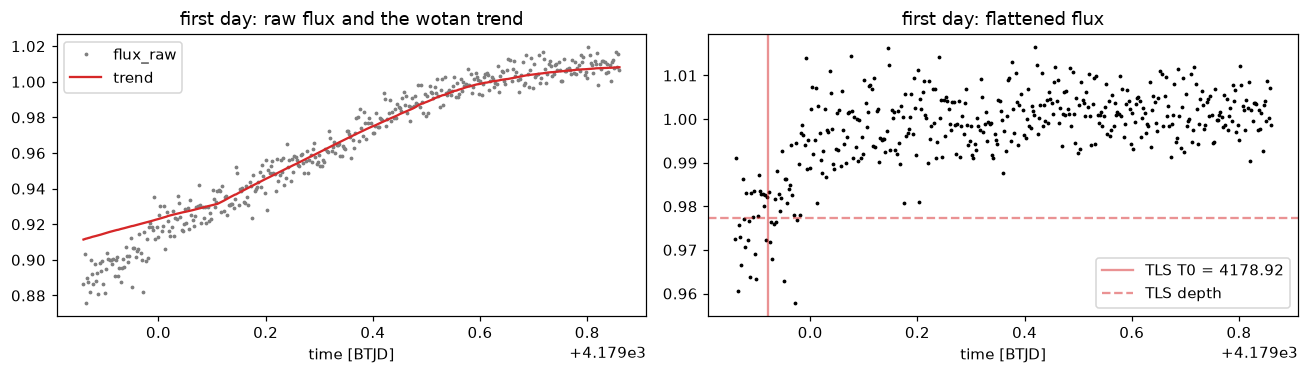

In [9]:
first_day = lc[lc["time"] < lc["time"].min() + 1.0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(first_day["time"], first_day["flux_raw"], ".", ms=3, color="0.5", label="flux_raw")
axes[0].plot(first_day["time"], first_day["trend"], "-", color="C3", label="trend")
axes[0].set_title("first day: raw flux and the wotan trend"); axes[0].legend()
axes[1].plot(first_day["time"], first_day["flux"], ".", ms=3, color="k")
axes[1].axvline(results.T0, color="C3", alpha=0.5, label=f"TLS T0 = {results.T0:.2f}")
axes[1].axhline(results.depth, color="C3", ls="--", alpha=0.5, label="TLS depth")
axes[1].set_title("first day: flattened flux"); axes[1].legend()
for ax in axes: ax.set_xlabel("time [BTJD]")
plt.tight_layout()

The raw flux starts at ~0.88 and climbs by 12 % over the first day: a
start-of-orbit systematic (scattered light as the spacecraft comes off
perigee). The 0.5-day biweight removes most of it, but at the very edge the
window is one-sided and a ~2 % residual is left. TLS, which has no idea what an
edge is, finds the deepest thing in the light curve, and with `period_max =
span / 2` it can always place the "second transit" in the gap.

Lessons that go straight into `search.py` and `vet.py`:

1. **SDE alone is not a detection.** Always store `distinct_transit_count`,
   `empty_transit_count`, `transit_depths` and `period_unc`; vetting must require
   `distinct_transit_count ≥ 2` (plan §7, "Transit count").
2. A best period at (or within a few grid steps of) `period_max` with one
   populated transit is the signature of a single event — an edge artefact, a
   flare-like feature, or, rarely, a genuine single transit of a long-period
   planet (milestone B, not this one).
3. This is also feedback for step 3: trimming the first/last ~0.25 d of each
   orbit, or masking the scattered-light windows from the Data Release Notes,
   would remove this class of false positive before it reaches TLS. Do not fix
   it in `search.py`; note it and handle it in `detrend.py`/`vet.py`.

## 5. The three plots you should always look at

1. **Periodogram** — SDE vs period. A real signal is a *sharp* spike standing
   clearly above the forest, often with smaller peaks at P/2, 2P, 3P (aliases).
   Noise gives a forest of similar-height peaks with no dominant one.
2. **Phase-folded light curve** — the data folded on `period`, with the
   template. A real transit is a clear, U-shaped dip at phase 0.5 that the
   binned points follow. Noise: the "dip" is just a few low points.
3. **Flattened light curve with transit marks** — do the predicted transit
   times coincide with visible dips, and are they avoiding gaps/edges?

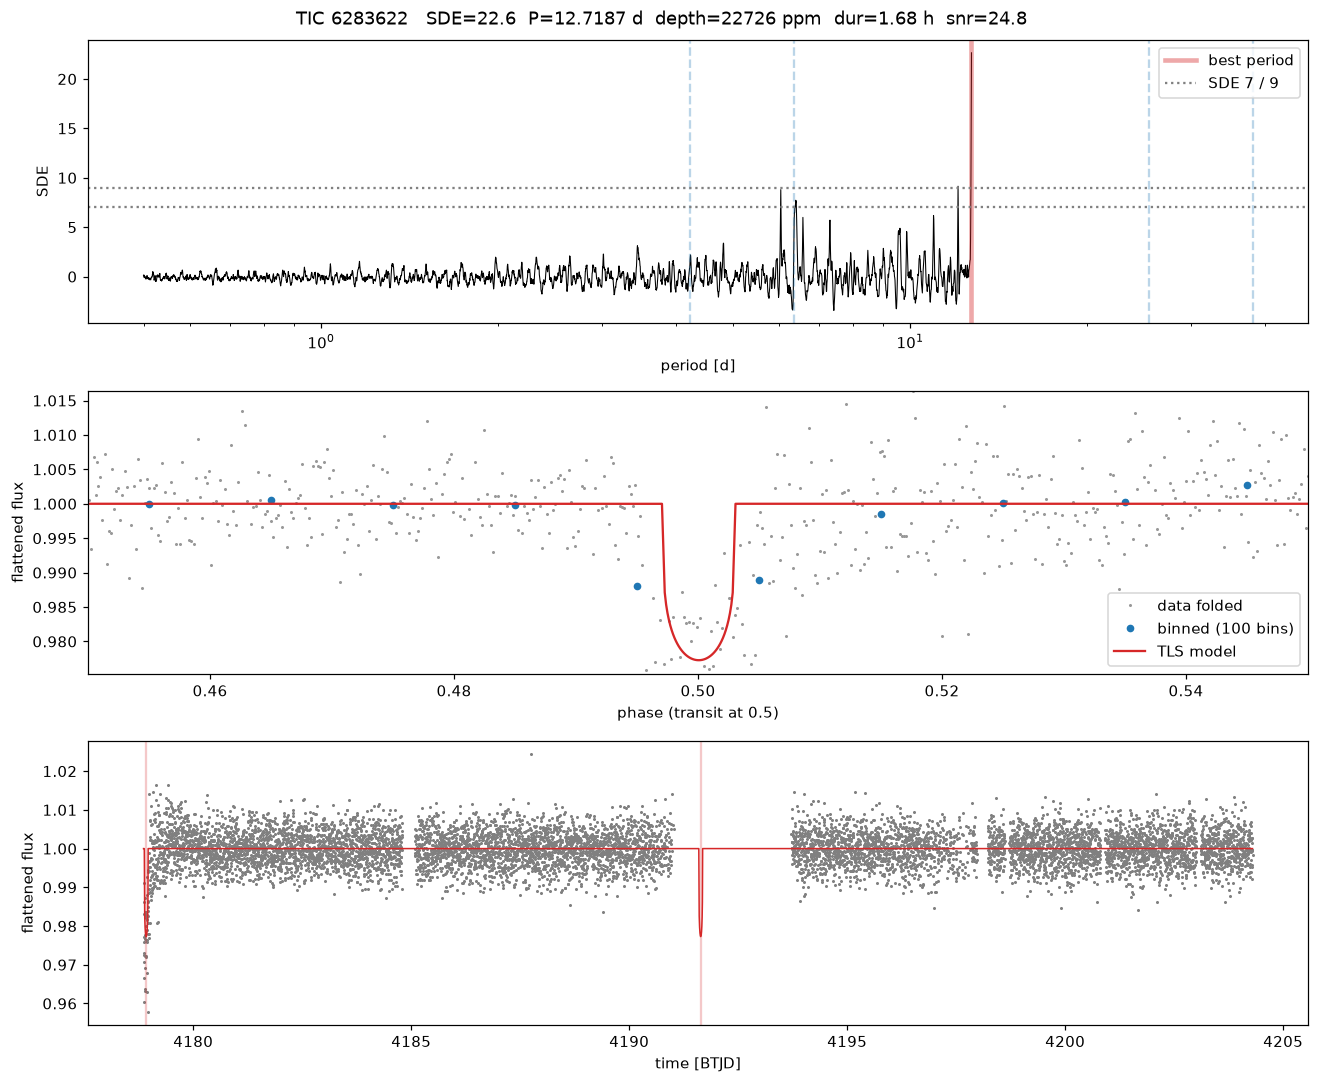

In [10]:
def plot_tls(tic_id, t, y, r, title_extra=""):
    fig, axes = plt.subplots(3, 1, figsize=(12, 10))
    fig.suptitle(f"TIC {tic_id}   SDE={r.SDE:.1f}  P={r.period:.4f} d  depth={(1-r.depth)*1e6:.0f} ppm  "
                 f"dur={r.duration*24:.2f} h  snr={r.snr:.1f} {title_extra}")

    # 1. periodogram
    ax = axes[0]
    ax.plot(r.periods, r.power, "k-", lw=0.7)
    ax.axvline(r.period, color="C3", alpha=0.4, lw=3, label="best period")
    for n in (2, 3):  # aliases: where you would expect secondary peaks
        ax.axvline(r.period * n, color="C0", alpha=0.3, ls="--")
        ax.axvline(r.period / n, color="C0", alpha=0.3, ls="--")
    ax.axhline(7, color="0.5", ls=":", label="SDE 7 / 9")
    ax.axhline(9, color="0.5", ls=":")
    ax.set_xscale("log"); ax.set_xlabel("period [d]"); ax.set_ylabel("SDE"); ax.legend(loc="upper right")

    # 2. phase fold with the model and binned points
    ax = axes[1]
    ax.plot(r.folded_phase, r.folded_y, ".", ms=2, color="0.6", label="data folded")
    nb = 100
    bins = np.linspace(0, 1, nb + 1)
    idx = np.digitize(r.folded_phase, bins) - 1
    binned = np.array([np.nanmean(r.folded_y[idx == i]) if np.any(idx == i) else np.nan for i in range(nb)])
    ax.plot(0.5 * (bins[1:] + bins[:-1]), binned, "o", ms=4, color="C0", label=f"binned ({nb} bins)")
    ax.plot(r.model_folded_phase, r.model_folded_model, "-", color="C3", label="TLS model")
    w = max(3 * r.duration / r.period, 0.05)  # zoom to a few durations around the transit
    ax.set_xlim(0.5 - w, 0.5 + w)
    lo = np.nanpercentile(r.folded_y, 0.5); ax.set_ylim(min(lo, r.depth) - 0.002, 1 + (1 - lo))
    ax.set_xlabel("phase (transit at 0.5)"); ax.set_ylabel("flattened flux"); ax.legend(loc="lower right")

    # 3. light curve with predicted transit times
    ax = axes[2]
    ax.plot(t, y, ".", ms=2, color="0.5")
    ax.plot(r.model_lightcurve_time, r.model_lightcurve_model, "-", color="C3", lw=1)
    for tt in r.transit_times:
        ax.axvline(tt, color="C3", alpha=0.25)
    ax.set_xlabel("time [BTJD]"); ax.set_ylabel("flattened flux")
    plt.tight_layout()

plot_tls(stars[0], t, y, results)

## 6. Turn it into a function, run it on the four stars

This is the shape of `search_one()` in `search.py`: load one flattened light
curve, look up `rad`/`mass`, run TLS, return one flat dict/dataclass of
scalars. Everything array-valued is either dropped or stored as a list
(`transit_depths`, `transit_times` — parquet handles list columns fine and they
are useful in vetting).

Things to notice that `search.py` must handle:

- **Timing**: record `runtime_s` per star. It lets you estimate the full-sector
  run and spot pathological light curves.
- **Errors**: catch everything, store `status="error"` and the message, like
  `detrend.py` does. TLS raises on too few points, unsorted time, or
  `R_star` outside its bounds.
- **`time_span`** is per star (gaps and edge-trimming differ), so `period_max`
  is computed per star.

In [11]:
def search_one(tic_id: int) -> dict:
    row = {"tic_id": tic_id, "status": "error", "error": ""}
    try:
        lc = load_flat(tic_id)
        t, y, dy = cleaned_array(lc["time"].values, lc["flux"].values, lc["flux_err"].values)
        span = t.max() - t.min()
        p = tls_params(targets.loc[tic_id, "rad"], targets.loc[tic_id, "mass"], span)
        t0 = time.time()
        r = transitleastsquares(t, y, dy).power(**p)
        row.update(summarize(r))
        row.update(
            n_points=len(t),
            time_span=span,
            transit_times=list(r.transit_times),
            transit_depths=list(r.transit_depths),
            runtime_s=time.time() - t0,
            status="ok",
        )
        row["_results"] = r  # keep the full object for plotting in the notebook only; do NOT store in search.py
    except Exception as e:
        row["error"] = f"{type(e).__name__}: {e}"
    return row

rows = [search_one(tic) for tic in stars]
table = pd.DataFrame(rows).drop(columns=["_results"])
table.set_index("tic_id")[
    ["status", "SDE", "snr", "period", "depth_ppm", "duration_h", "transit_count",
     "distinct_transit_count", "odd_even_mismatch", "FAP", "runtime_s"]
]

/home/jj/Desktop/science-projects/exoplanets-research/.venv/lib/python3.14/site-packages/transitleastsquares/main.py:411: UserWarning: 1 of 2 transits without data. The true period may be twice the given period.
  warnings.warn(text)
/home/jj/Desktop/science-projects/exoplanets-research/.venv/lib/python3.14/site-packages/transitleastsquares/main.py:411: UserWarning: 1 of 3 transits without data. The true period may be twice the given period.
  warnings.warn(text)


,status,SDE,snr,period,depth_ppm,duration_h,transit_count,distinct_transit_count,odd_even_mismatch,FAP,runtime_s
tic_id,,,,,,,,,,,
6283622,ok,22.649348,24.775556,12.718744,22725.814308,1.681830,2,1,NaN,0.000080,23.365112
6283851,ok,5.633327,2.782789,0.593966,640.529608,0.186520,42,35,0.125581,NaN,18.944443
6283857,ok,7.153664,5.675630,12.182242,6315.706132,1.958068,3,2,NaN,0.007443,22.096959
6284143,ok,6.015739,5.612469,11.995147,2281.607971,2.403434,3,3,0.587619,0.055062,16.111359


This DataFrame (minus `_results`) is **the table `search.py` writes to
`data/search/sector_104.parquet`**. One row per star, nothing filtered.

Now look at all four with the plots. What the table says:

- **TIC 6283622** — the edge artefact from §4: high SDE, one populated transit at `period_max`.
- **TIC 6283851** — SDE 5.6, `snr` 2.8, a 640 ppm "dip" of 0.19 h on a 2,500 ppm-scatter star: noise. Note `FAP = NaN`, i.e. below the table.
- **TIC 6283857** — SDE 7.2 at 12.2 d, 2 of 3 transits populated, 6,300 ppm depth on a 6,600 ppm-scatter star with `contratio = 2.7`: right at the threshold, and the plots show why it should not excite you.
- **TIC 6284143** — SDE 6.0: noise.

Three of four are what the bulk of the sector will look like: SDE 5–7, a
periodogram with no dominant peak, a fold where the "transit" is a few low
points. Learn that picture; it is the background against which a real signal
(§8) stands out.

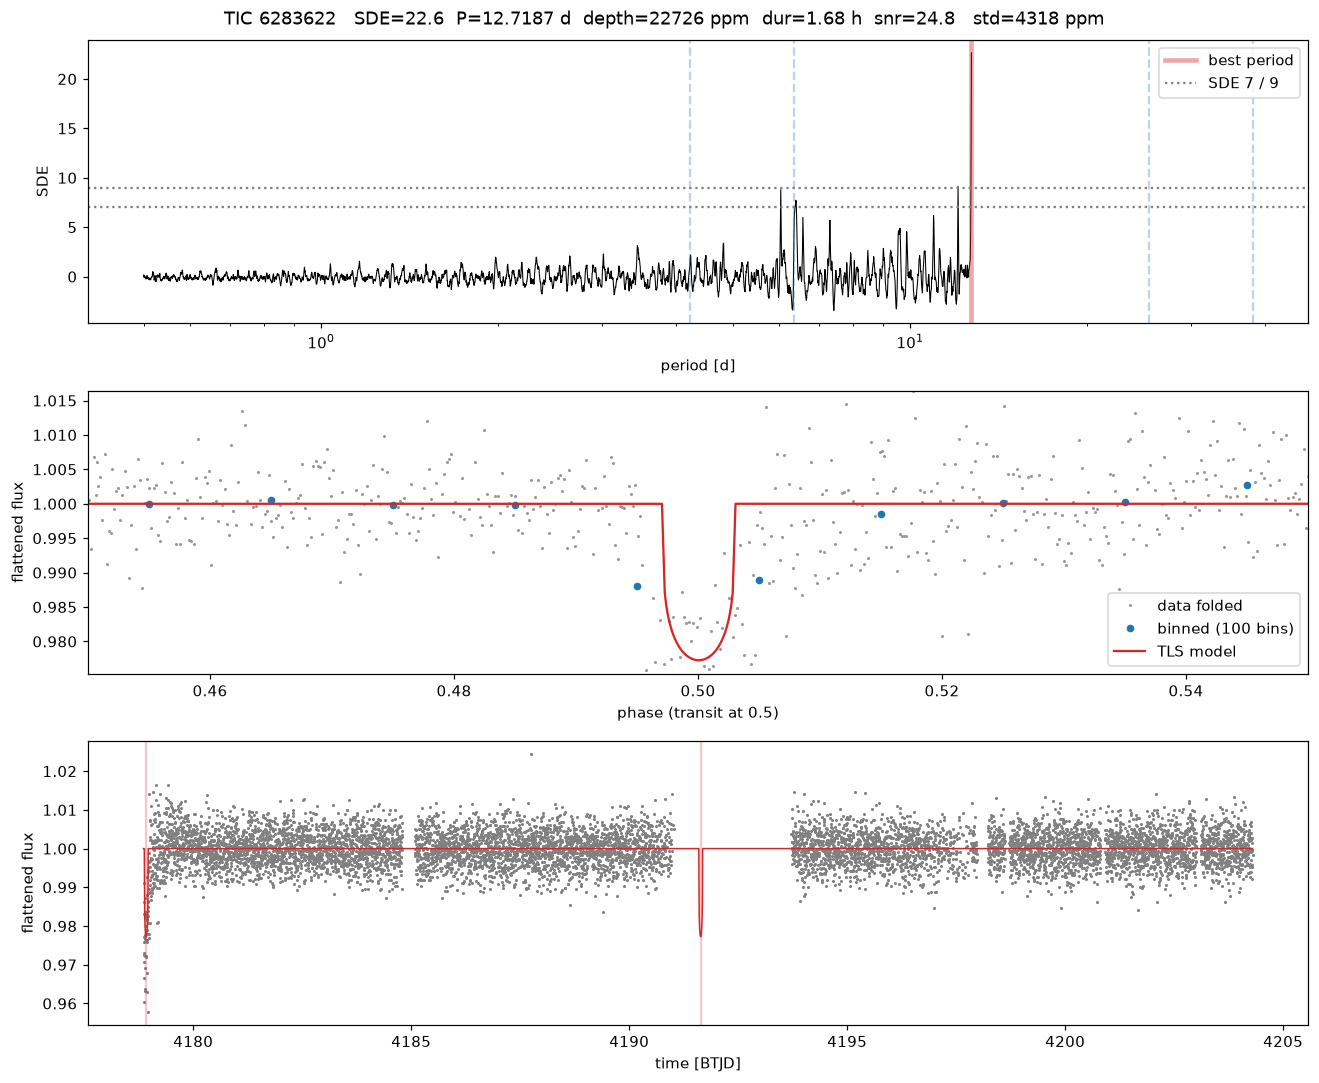

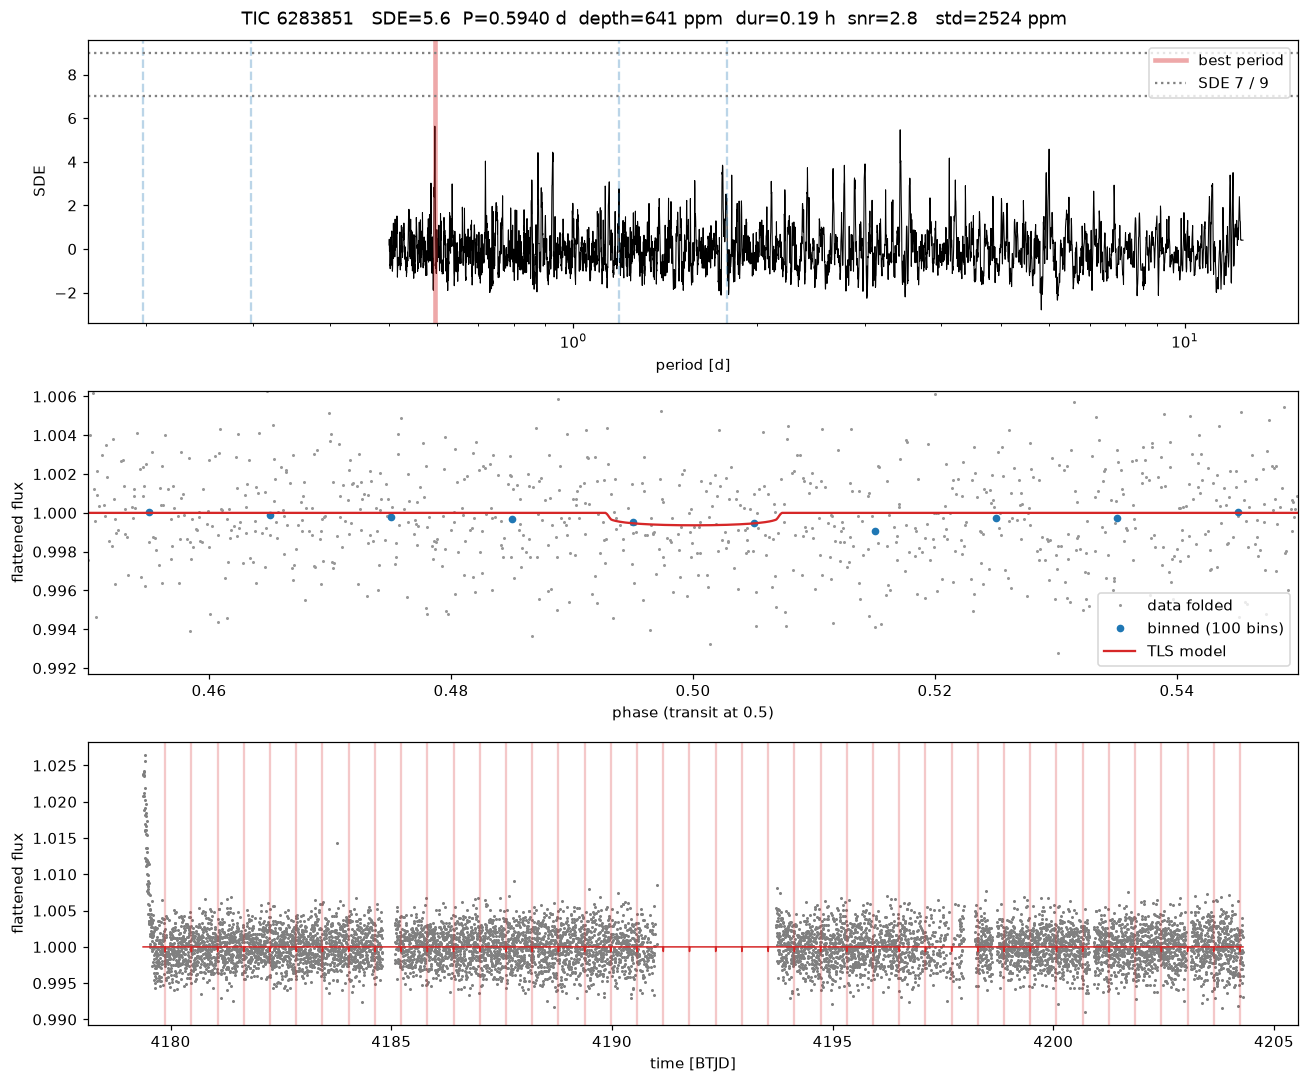

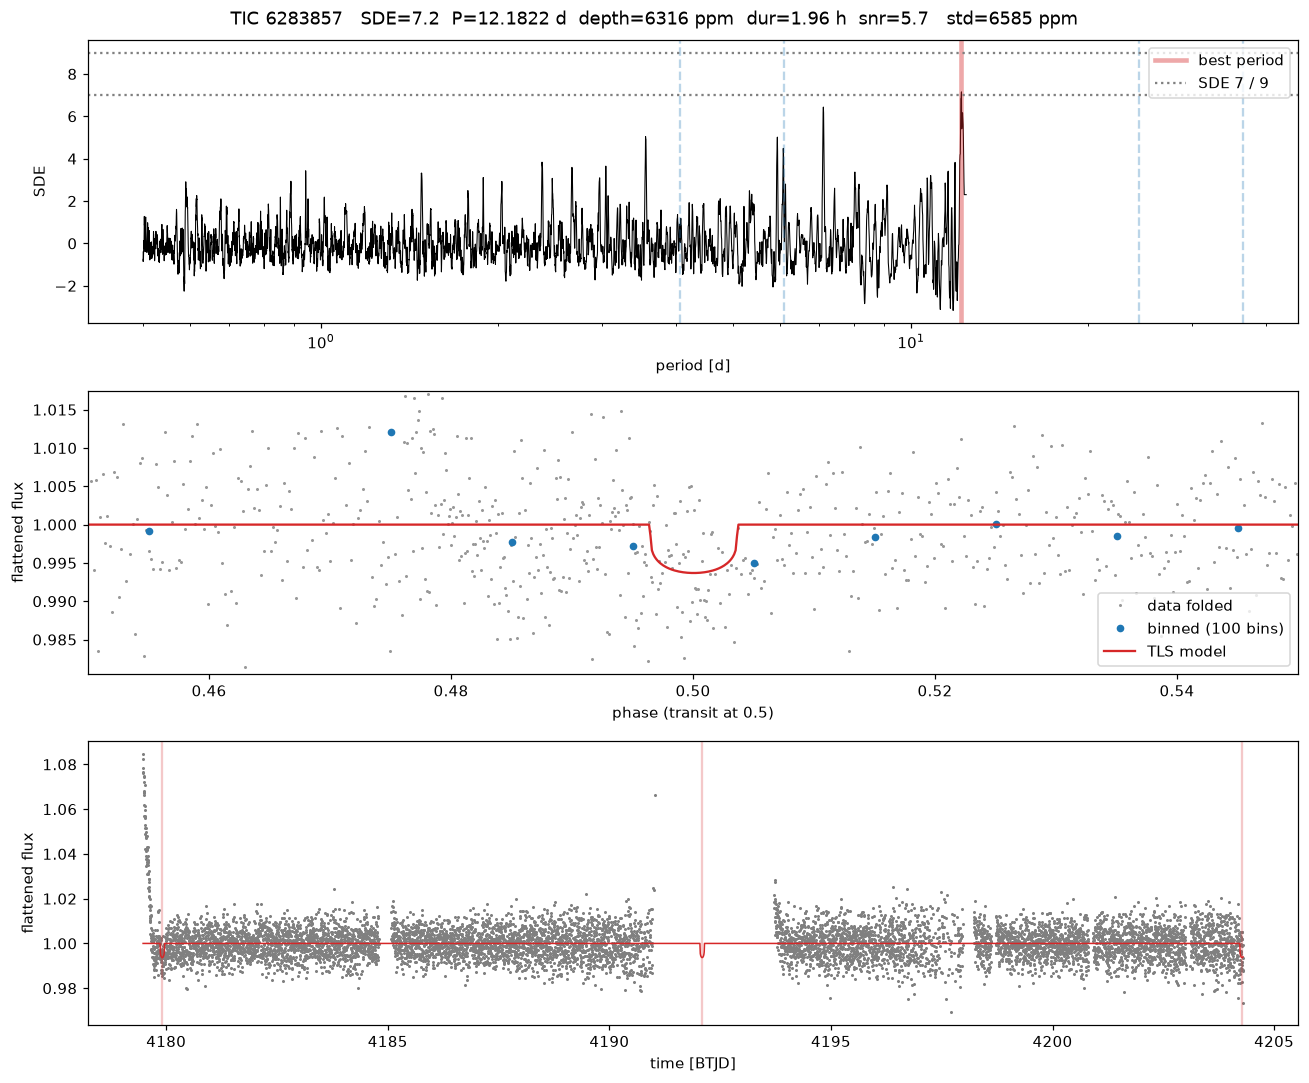

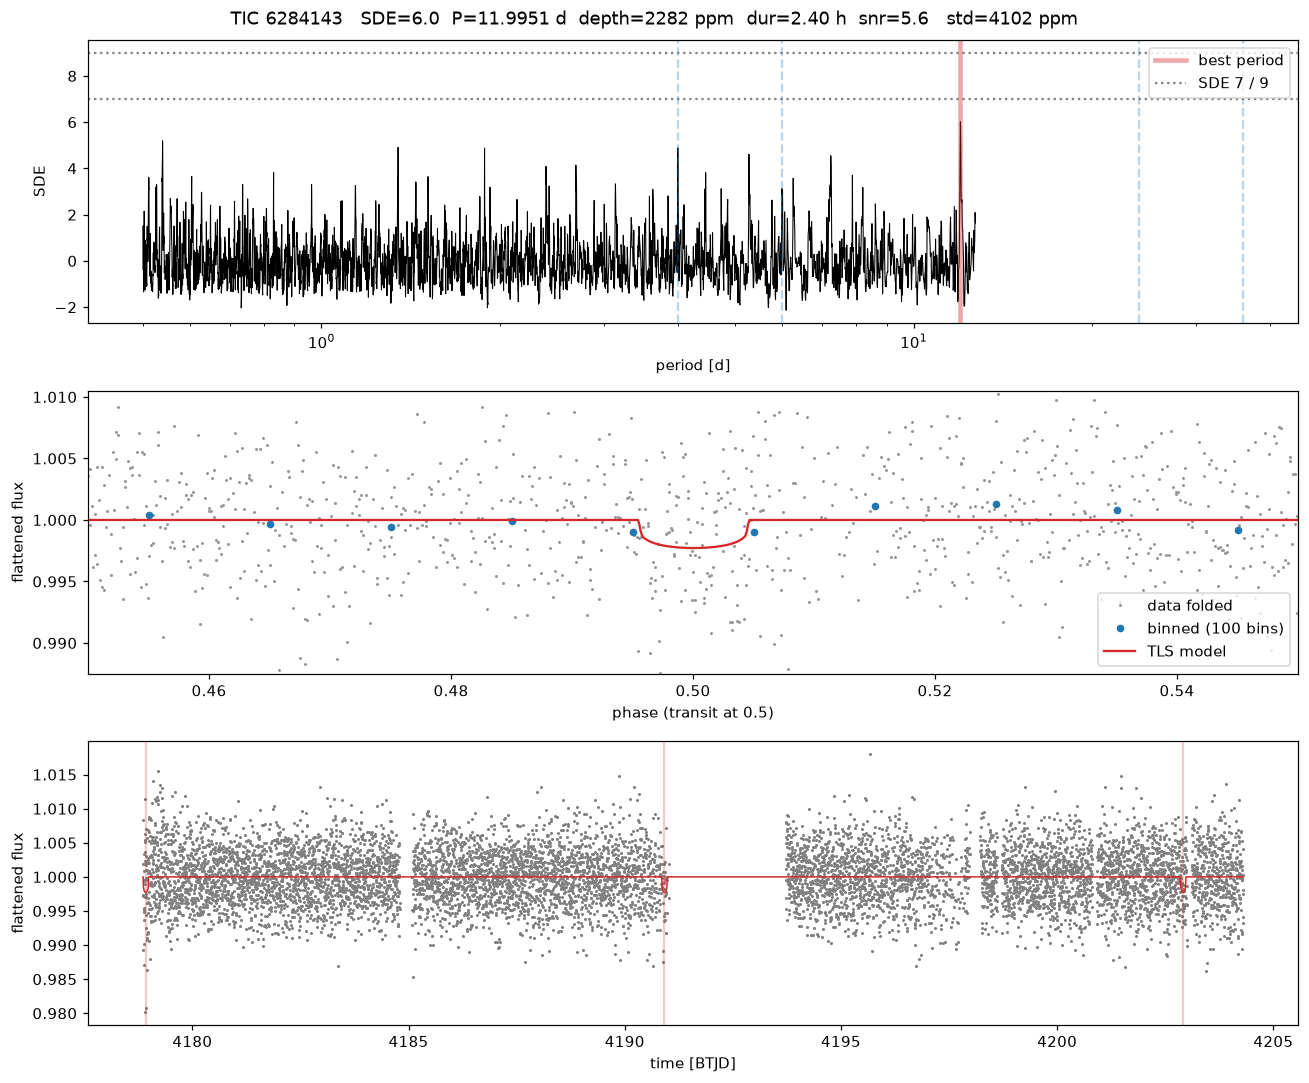

In [12]:
for row in rows:
    if row["status"] == "ok":
        r = row["_results"]
        lc_i = load_flat(row["tic_id"])
        plot_tls(row["tic_id"], lc_i["time"].values, lc_i["flux"].values, r,
                 title_extra=f"  std={overview.loc[row['tic_id'], 'std_flat']:.0f} ppm")
    else:
        print(row["tic_id"], row["error"])

Scaling: sum the `runtime_s` column and divide by four → seconds per star.
Multiply by 4,694 stars and divide by the number of workers to estimate the
full-sector run (the plan's estimate is ~1 h on 8 cores).

In [12]:
per_star = table["runtime_s"].mean()
n_total = (detrend["status"] == "ok").sum()
for workers in (1, 4, 8, os.cpu_count()):
    print(f"{workers:2d} workers: ~{per_star * n_total / workers / 60:.0f} min for {n_total} stars")

 1 workers: ~1575 min for 4694 stars
 4 workers: ~394 min for 4694 stars
 8 workers: ~197 min for 4694 stars
12 workers: ~131 min for 4694 stars


## 7. Optional second pass: mask the best signal and search again

Multi-planet systems are common around M dwarfs (TOI-270, L 98-59, TRAPPIST-1).
TLS reports only the single best period; a second planet is invisible unless
you remove the first signal and rerun. The recipe:

1. `transit_mask(t, period, 2 * duration, T0)` returns a boolean array that is
   `True` inside every predicted transit of the first signal (we use twice the
   duration for margin).
2. Drop those points and run TLS again on the rest.

It doubles the runtime, so the plan marks it optional. Doing it *only for stars
whose first-pass SDE was high* is a good compromise — a second pass on a star
with no first signal is just a second draw from the noise. Here it is on the
first star, purely to show the mechanics.

In [13]:
r1 = rows[0]["_results"]
in_transit = transit_mask(t, r1.period, 2 * r1.duration, r1.T0)
print(f"masking {in_transit.sum()} of {len(t)} points ({in_transit.mean()*100:.1f} %)")

t2, y2, dy2 = t[~in_transit], y[~in_transit], dy[~in_transit]
r2 = transitleastsquares(t2, y2, dy2).power(**tls_params(targets.loc[stars[0], "rad"], targets.loc[stars[0], "mass"], t2.max() - t2.min()))
pd.DataFrame({"pass 1": summarize(r1), "pass 2": summarize(r2)})

masking 62 of 8794 points (0.7 %)


,pass 1,pass 2
SDE,2.264935e+01,5.744537
SDE_raw,7.922182e+00,5.163012
FAP,8.003200e-05,0.086114
snr,2.477556e+01,3.865530
period,1.271874e+01,2.067009
period_unc,inf,0.002556
T0,4.178921e+03,4179.023318
duration_h,1.681830e+00,0.234445
depth_ppm,2.272581e+04,2216.766833
depth_mean_ppm,2.117138e+04,2523.000252


## 8. Complement: the same recipe on a star with a *known* planet

Everything above was on stars where, most likely, nothing is there. To calibrate
your eye, run the identical steps on a star we know has a transiting planet.
Our sector 104 target list happens to contain **LHS 3844** (TIC 410153553,
TOI-136), a 0.19 R☉ M dwarf at 15 pc with a rocky planet discovered by TESS in
sector 1 (Vanderspek et al. 2019):

| | value |
|---|---|
| period | 0.46293 d (11.1 h) |
| depth | ~ 4,500 ppm |
| duration | ~ 0.53 h |

Its flattened light curve is already in `data/lc_flat/` — same file format, same
detrending, same `search_one()` — so this is exactly what `search.py` will see
for this star. Nothing is downloaded.

But notice the period: **0.463 d is below the `period_min = 0.5` we set in
§3**. With the plan's default this planet is *invisible* to the search. That is
the first thing to demonstrate. We call TLS twice: once with our `tls_params`
as they stand, once with `period_min` lowered to 0.2 d.

What to expect in the second run: a spike with SDE ≫ 10 at 0.463 d, a clean
U-shaped fold, ~50 transits with consistent per-transit depths,
`odd_even_mismatch` small. That is the reference picture for "a real detection",
to compare with the four stars of §6.

In [14]:
KNOWN_TIC = 410153553  # LHS 3844 / TOI-136
lc_k = load_flat(KNOWN_TIC)
tk, yk, dyk = cleaned_array(lc_k["time"].values, lc_k["flux"].values, lc_k["flux_err"].values)
rad_k, mass_k = targets.loc[KNOWN_TIC, "rad"], targets.loc[KNOWN_TIC, "mass"]
print(pd.concat([ok.set_index("tic_id").loc[[KNOWN_TIC], ["n_out", "std_flat"]],
                 targets.loc[[KNOWN_TIC], ["tmag", "teff", "rad", "mass", "dist_pc"]],
                 manifest.loc[[KNOWN_TIC], ["author", "cadence_s"]]], axis=1).T)

# run 1: the parameters exactly as in §3 (period_min = 0.5 d)
p_k = tls_params(rad_k, mass_k, tk.max() - tk.min())
rk_default = transitleastsquares(tk, yk, dyk).power(**p_k)
print(f"period_min = {p_k['period_min']}: SDE {rk_default.SDE:.1f} at P = {rk_default.period:.4f} d  "
      f"(the true period 0.4629 d is outside the grid -> TLS can only find its alias or noise)")

tic_id       410153553
n_out            15888
std_flat   3382.060265
tmag           11.9238
teff            3004.0
rad           0.188624
mass          0.157909
dist_pc        14.8846
author            SPOC
cadence_s        120.0
period_min = 0.5: SDE 22.8 at P = 0.9259 d  (the true period 0.4629 d is outside the grid -> TLS can only find its alias or noise)


per-transit depths (first 12): [0.9969 0.9974 0.9963 0.9938 0.9954 0.9972 0.996  0.9946 0.9969 0.9961
 0.9945 0.9945]


,period_min = 0.5,period_min = 0.2
SDE,22.846146,32.044288
SDE_raw,20.968642,30.477642
FAP,0.000080,0.000080
snr,23.320977,33.008224
period,0.925916,0.462970
period_unc,0.001282,0.000572
T0,4180.612295,4180.149004
duration_h,0.492976,0.471273
depth_ppm,4630.534661,4652.855027
depth_mean_ppm,4262.358458,4280.366535


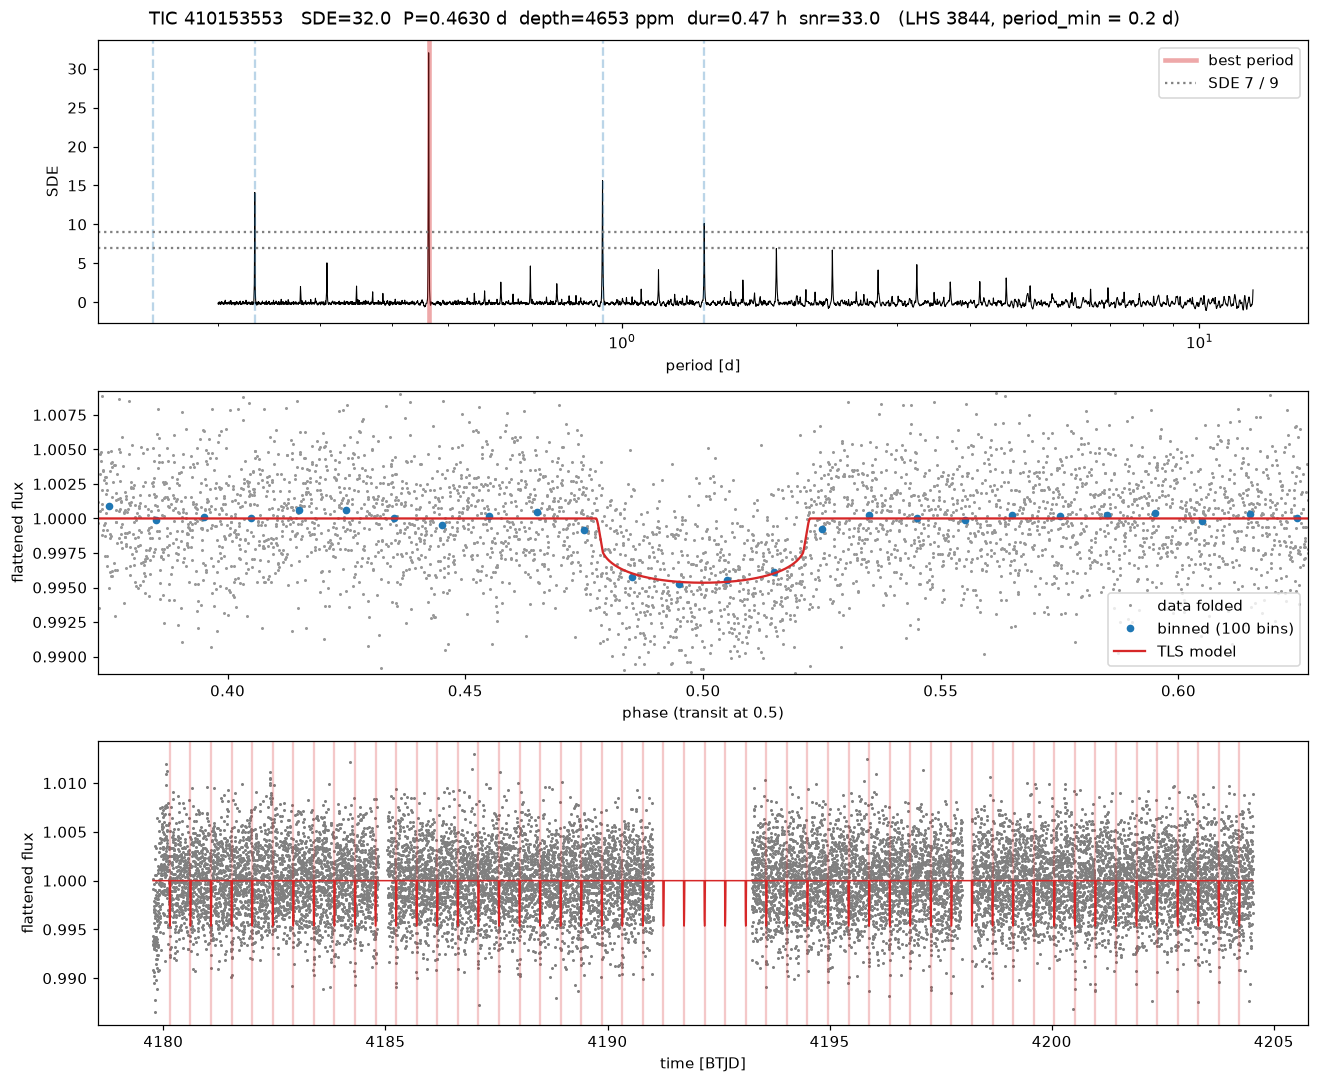

In [15]:
# run 2: same star, period_min lowered so the true period is inside the grid
rk = transitleastsquares(tk, yk, dyk).power(**{**p_k, "period_min": 0.2})
plot_tls(KNOWN_TIC, tk, yk, rk, title_extra="  (LHS 3844, period_min = 0.2 d)")
print("per-transit depths (first 12):", np.round(rk.transit_depths[:12], 4))
pd.DataFrame({"period_min = 0.5": summarize(rk_default), "period_min = 0.2": summarize(rk)})

Compare this with the four stars of §6: the periodogram spike vs the forest, the
fold, `SDE`/`snr`, the per-transit depths. That contrast is the whole point of
the search step — and the reason the thresholds are decided in vetting, with
injection/recovery, not hard-coded in `search.py`.

Also a lesson for the parameters: the `period_min = 0.5` in the plan is a
convenience, not physics. Ultra-short-period planets around M dwarfs are a real
population (LHS 3844 b, GJ 1252 b, TOI-1685 b...). Short periods add few grid
points (the Ofir grid is dense at long periods, sparse at short ones), so
lowering `period_min` to ~0.2 d costs little. Check the `n_periods` row above.

Second pass on this star: mask planet b and search the residuals, as in §7.
LHS 3844 has no known second transiting planet, so ideally this returns a
noise-level SDE. Look carefully at what it returns instead.

/home/jj/Desktop/science-projects/exoplanets-research/.venv/lib/python3.14/site-packages/transitleastsquares/main.py:411: UserWarning: 1 of 2 transits without data. The true period may be twice the given period.
  warnings.warn(text)


,pass 1,pass 2 (b masked)
SDE,32.044288,1.491638e+01
SDE_raw,30.477642,1.061779e+01
FAP,0.000080,8.003200e-05
snr,33.008224,8.913681e+00
period,0.462970,1.238044e+01
period_unc,0.000572,inf
T0,4180.149004,4.179835e+03
duration_h,0.471273,1.700026e+00
depth_ppm,4652.855027,4.657364e+03
depth_mean_ppm,4280.366535,4.170632e+03


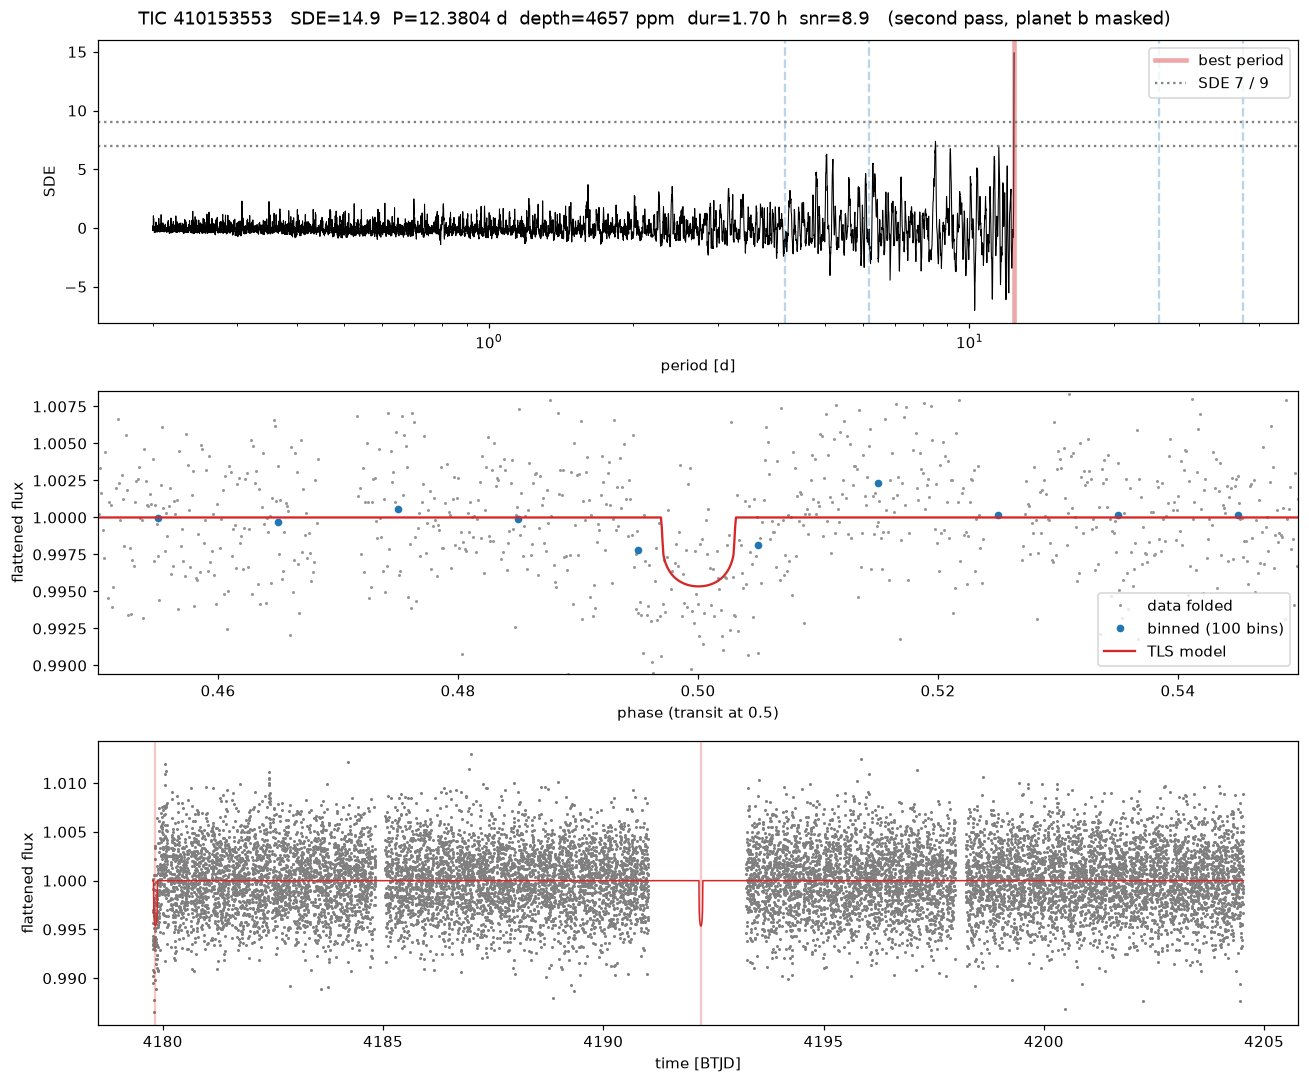

In [16]:
mask_k = transit_mask(tk, rk.period, 2 * rk.duration, rk.T0)
rk2 = transitleastsquares(tk[~mask_k], yk[~mask_k], dyk[~mask_k]).power(**{**p_k, "period_min": 0.2})
plot_tls(KNOWN_TIC, tk[~mask_k], yk[~mask_k], rk2, title_extra="  (second pass, planet b masked)")
pd.DataFrame({"pass 1": summarize(rk), "pass 2 (b masked)": summarize(rk2)})

The second pass reports SDE ≈ 15 — and it is the §4 trap again: `period ≈ 12.4 d`
(≈ `period_max`), `distinct_transit_count = 1`, `period_unc = inf`, a single
4,600 ppm event. Two stars out of five, both flagged by the same three fields.
When you write vetting, the rule `distinct_transit_count ≥ 2` will remove both;
when you tune detrending, edge trimming will remove them earlier.

## 9. Checklist for writing `src/search.py`

Follow the structure of `detrend.py` (module docstring with usage, `DATA_DIR`
from `.env`, a dataclass row, `_worker_logging()`, `search_one()`,
`search_sector()`, `main()` with argparse).

**Input**: `data/targets/sector_{N}_detrend.parquet` rows with `status == "ok"`
(the `file_path` column points to the flattened parquet) + `rad`, `mass` from
`data/targets/sector_{N}.parquet`.

**`search_one(tic_id, flat_file, rad, mass, ...) -> SearchRow`**

- `cleaned_array` → `tls_params` (per-star `period_max = span / 2`; explicit `R_star_min`/`M_star_min` bounds) → `power()` with `use_threads=1`, no progress bar, not verbose.
- Fill the row with the fields of `summarize()` plus `n_points`, `time_span`, `transit_times`, `transit_depths`, `runtime_s`, `status`, `error`.
- Store `depth_ppm = (1 − depth) × 1e6` and `duration_h = duration × 24` — do not store TLS's raw `depth`, it will be misread.
- Always store `distinct_transit_count`, `empty_transit_count`, `period_unc`, `transit_depths` — §4 and §8 showed that a high SDE with one populated transit is the most common false positive in this data.
- `try/except Exception` → `status="error"`, message in `error`. Never let one star kill the run.
- Optional `--second-pass`: `transit_mask` + rerun; store as `period_2, SDE_2, ...` columns, or as a second row with a `pass` column.

**`search_sector(sector, n_jobs, limit, force)`**

- `joblib.Parallel(n_jobs=n_jobs)` over stars, exactly like `detrend_sector`. TLS is CPU-bound, so `n_jobs` = number of physical cores is fine (unlike `fetch.py`, where MAST rate-limits).
- Resume logic: skip stars already present in the output parquet unless `--force` (merge old + new rows like `detrend_sector` does).
- Write `data/search/sector_{N}.parquet`, sorted by `tic_id`. **No SDE threshold.**
- Log per star: `TIC, SDE, period, depth_ppm, runtime`; at the end: count ok/error, median runtime, and the number of stars with `SDE > 9` as a sanity figure (expect a few percent, mostly false positives).

**CLI**: `--sector`, `--n-jobs`, `--limit`, `--force`, `--period-min`, `--period-max` (default `span/2`), `--oversampling`, `--second-pass`.

**Sanity checks before trusting the output** (plan §6):

1. Run `--limit 50`, check the runtime scaling and that `status == "ok"` for all.
2. Confirm the known TOIs in the sector are recovered with the right period (§8 did it by hand for LHS 3844; `search.py` must reproduce that row — and it will only do so if `period_min` is below 0.46 d). Other confirmed planets in the sector 104 target list you can check: TOI-122 (TIC 231702397, P = 5.078 d), TOI-177 (TIC 262530407, P = 2.853 d), TOI-134 (TIC 234994474, P = 1.4015 d, only ~600 ppm — a good test of the sensitivity limit).
3. Injection/recovery on ~50 stars (a later notebook): inject box transits of known depth/period into real flattened light curves, run `search_one`, and measure the recovered fraction. This calibrates the SDE threshold vetting will use.